In [6]:
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


# 1. Read data

In [7]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/"

In [8]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*02:01']

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [9]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions


NUM_RUNS = 5

## 2.2 Train
### 2.2.1 Train 8-mer
#### 2.2.1.1 baum-welch

In [10]:
%%time
TARGET_LENGTHS = [8]
algorithm = 'baum-welch'

per_allele_models = dict()
per_allele_histories = dict()
for run_num in range(NUM_RUNS):
    print(f"run {run_num}")
    for allele_name in ALLELES:
        print()
        per_kfold_per_length_data =  per_allele_per_kfold_per_length_binders_train[allele_name]
        models, histories = train_model(allele_name,
                                        per_kfold_per_length_data,
                                        TARGET_LENGTHS,
                                        verbose=False,
                                        multiple_check_input=False,
                                        algorithm=algorithm,
                                        name_prefix=f"{run_num}_run"
                                        )
        per_allele_models[allele_name] = models
        per_allele_histories[allele_name] = histories
        # save models
        for split_num, model in per_allele_models[allele_name].items():
            history = per_allele_histories[allele_name][split_num]
            save_model(model,history, TARGET_PATH_TO_RESULTS)


run 0

split 0
train size 2392
Shuffling for fairness 
Init batch size is 239


IndexError: list index out of range

#### 2.2.1.1 viterbi


In [12]:
%%time
TARGET_LENGTHS = [8]
algorithm = 'viterbi'

per_allele_models = dict()
per_allele_histories = dict()
for run_num in range(NUM_RUNS):
    print(f"run {run_num}")
    for allele_name in ALLELES:
        print()
        per_kfold_per_length_data =  per_allele_per_kfold_per_length_binders_train[allele_name]
        models, histories = train_model(allele_name,
                                        per_kfold_per_length_data,
                                        TARGET_LENGTHS,
                                        verbose=True,
                                        multiple_check_input=True,
                                        algorithm=algorithm,
                                        name_prefix=f"{run_num}_run",
                                        batches_per_epoch=5,
                                        batch_size=50,

                                        )
        per_allele_models[allele_name] = models
        per_allele_histories[allele_name] = histories
        # save models
        for split_num, model in per_allele_models[allele_name].items():
            history = per_allele_histories[allele_name][split_num]
            save_model(model,history, TARGET_PATH_TO_RESULTS)


run 0

split 0
train size 2392
Shuffling for fairness 
Init batch size is 1
[1] Improvement: -inf	Time (s): 0.004001
[2] Improvement: nan	Time (s): 0.008013
[3] Improvement: nan	Time (s): 0.007994
[4] Improvement: nan	Time (s): 0.007992
[5] Improvement: nan	Time (s): 0.004001
[6] Improvement: nan	Time (s): 0.007998
[7] Improvement: nan	Time (s): 0.008
[8] Improvement: nan	Time (s): 0.004
[9] Improvement: nan	Time (s): 0.004002
[10] Improvement: nan	Time (s): 0.007999
[11] Improvement: nan	Time (s): 0.008
[12] Improvement: nan	Time (s): 0.004001
[13] Improvement: nan	Time (s): 0.007998
[14] Improvement: nan	Time (s): 0.007998
[15] Improvement: nan	Time (s): 0.004001
[16] Improvement: nan	Time (s): 0.008001
[17] Improvement: nan	Time (s): 0.007999
[18] Improvement: nan	Time (s): 0.004001
[19] Improvement: nan	Time (s): 0.003999
[20] Improvement: nan	Time (s): 0.008
[21] Improvement: nan	Time (s): 0.004
[22] Improvement: nan	Time (s): 0.008001
[23] Improvement: nan	Time (s): 0.004002
[24]

In [5]:
model = per_allele_models[allele_name][1]
with open("state_graph.png", 'w+') as f:
    model.plot(file=f, crop_zero=True)

NameError: name 'per_allele_models' is not defined

In [15]:
import numpy as np
from pomegranate.io import DataGenerator, SequenceGenerator, BaseGenerator
from pomegranate import DiscreteDistribution, IndependentComponentsDistribution, HiddenMarkovModel
allele_name = ALLELES[0]
train_data = per_allele_per_kfold_per_length_binders_train[allele_name][1][8]
sample_X = np.array([[char for char in item] for item in train_data], dtype=object)
X = DataGenerator(sample_X)



In [16]:
distribution=DiscreteDistribution
end_state=True
n_components=12
initialization_batch_size = 1
labels = None
weights=None
keys=None
random_state=None

In [17]:
if not isinstance(X, BaseGenerator):
    data_generator = SequenceGenerator(X, weights, labels)
else:
    data_generator = X

if initialization_batch_size is None:
    initialization_batch_size = len(data_generator)

X_, labels_ = [], []
data = data_generator.batches()
for i in range(initialization_batch_size):
    batch = next(data)

    X_.extend(batch[0])
    if labels is not None:
        labels_.extend(batch[2])

In [18]:
from pomegranate.hmm import check_random_state
random_state = check_random_state(random_state)

In [19]:
if distribution is DiscreteDistribution:
    X_concat = np.concatenate(X_)

    if keys is None:
        if X_concat.ndim == 1:
            keys = np.unique(X_concat)
        else:
            keys = [np.unique(X_concat[:,i] for i in range(X_concat.shape[1]))]

    distributions = []
    for i in range(n_components):
        weights = random_state.uniform(0, 1, size=len(keys))
        weights /= weights.sum()

        if X_concat.ndim == 1:
            distribution = DiscreteDistribution({key: weight for key, weight in zip(keys, weights)})
        else:
            distribution = IndependentComponentsDistribution.from_samples(X_concat,
                                                                          distributions=DiscreteDistribution)

        distributions.append(distribution)

In [20]:
k = n_components
transition_matrix = np.ones((k, k)) / k
start_probabilities = np.ones(k) / k

end_probabilities = None
if end_state:
    end_probabilities = np.ones(k) / k

state_names = [f"s{i}" for i in range(n_components)]
name = "test-model"
model = HiddenMarkovModel.from_matrix(transition_matrix, distributions,
                        start_probabilities, state_names=state_names, name=name,
                        ends=end_probabilities)

In [21]:
sequences = data_generator
if not isinstance(sequences, BaseGenerator):
    data_generator = SequenceGenerator(sequences, weights, labels)
else:
    print("here")
    data_generator = sequences
n = data_generator.shape[0]

semisupervised = False
if labels is not None:
    for l in labels:
        if l is None:
            semisupervised = True
            break

here


In [22]:
transition_pseudocount=0
emission_pseudocount=0.0
use_pseudocount=False
stop_threshold=1e-9
min_iterations=0
max_iterations=1e8
inertia=0.25
edge_inertia=0.0
distribution_inertia=0.0
pseudocount=None
algorithm='viterbi'

iteration = 0
mv = model.multivariate
improvement = np.inf
total_improvement = 0
initial_log_probability_sum = 0
log_probability_sum = 0
last_log_probability_sum = 0
alg = algorithm.lower()
check_input = alg == 'viterbi'
lr_decay = 0

In [23]:
_, history = model.fit(data_generator, weights=weights, labels=labels,
                       stop_threshold=stop_threshold, min_iterations=min_iterations,
                       max_iterations=max_iterations, algorithm=algorithm,
                       verbose=True, pseudocount=pseudocount,
                       transition_pseudocount=transition_pseudocount,
                       emission_pseudocount=emission_pseudocount,
                       use_pseudocount=use_pseudocount,
                       inertia=inertia, edge_inertia=edge_inertia,
                       distribution_inertia=distribution_inertia,
                       batches_per_epoch=None, lr_decay=lr_decay,
                       callbacks=[], return_history=True, n_jobs=1,
                       multiple_check_input=True)
model.bake()

Expected transitions
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
228.0
72.0
231.0
57.0
351.0
0.0
107.0
115.0
139.0
0.0
560.0
89.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
655.0
258.0
459.0
237.0
906.0
0.0
326.0
334.0
583.0
0.0
1921.0
968.0
0.0
80.0
39.0
96.0
22.0
100.0
0.0
43.0
35.0
80.0
0.0
290.0
86.0
0.0
116.0
87.0
148.0
55.0
211.0
0.0
95.0
118.0
140.0
0.0
449.0
569.0
0.0
64.0
27.0
87.0
28.0
77.0
0.0
38.0
31.0
73.0
0.0
216.0
66.0
0.0
218.0
120.0
391.0
95.0
355.0
0.0
155.0
127.0
262.0
0.0
941.0
215.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
114.0
45.0
124.0
38.0
110.0
0.0
73.0
55.0
102.0
0.0
366.0
141.0
0.0
130.0
35.0
111.0
28.0
143.0
0.0
58.0
52.0
82.0
0.0
350.0
75.0
0.0
182.0
77.0
156.0
68.0
286.0
0.0
119.0
74.0
186.0
0.0
539.0
184.0
0.0
162.0
111.0
185.0
79.0
340.0
0.0
154.0
123.0
224.0
0.0
1015.0
[1] Improvement: 4193.031359537432	Time (s): 0.182
Expected transitions
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
228.0
72.0
231.0


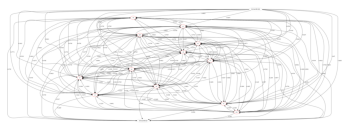

In [24]:
with open("state_graph.png", 'w+') as f:
    model.plot(file=f, crop_zero=True)

In [323]:
_, history = model.fit(data_generator, weights=weights, labels=labels,
                       stop_threshold=stop_threshold, min_iterations=min_iterations,
                       max_iterations=max_iterations, algorithm=algorithm,
                       verbose=True, pseudocount=pseudocount,
                       transition_pseudocount=transition_pseudocount,
                       emission_pseudocount=emission_pseudocount,
                       use_pseudocount=use_pseudocount,
                       inertia=inertia, edge_inertia=edge_inertia,
                       distribution_inertia=distribution_inertia,
                       batches_per_epoch=None, lr_decay=lr_decay,
                       callbacks=[], return_history=True, n_jobs=1,
                       multiple_check_input=True)
model.bake()

[1] Improvement: 0.0	Time (s): 0.05617
Total Training Improvement: 0.0
Total Training Time (s): 0.1114


In [324]:
_, history = model.fit(data_generator, weights=weights, labels=labels,
                       stop_threshold=stop_threshold, min_iterations=min_iterations,
                       max_iterations=max_iterations, algorithm=algorithm,
                       verbose=True, pseudocount=pseudocount,
                       transition_pseudocount=transition_pseudocount,
                       emission_pseudocount=emission_pseudocount,
                       use_pseudocount=use_pseudocount,
                       inertia=inertia, edge_inertia=edge_inertia,
                       distribution_inertia=distribution_inertia,
                       batches_per_epoch=None, lr_decay=lr_decay,
                       callbacks=[], return_history=True, n_jobs=1,
                       multiple_check_input=True)
model.bake()

[1] Improvement: 0.0	Time (s): 0.055
Total Training Improvement: 0.0
Total Training Time (s): 0.1110


In [325]:
model.dense_transition_matrix()

array([[0.06138306, 0.04428904, 0.17482517, 0.06682207, 0.04273504,
        0.11965812, 0.07847708, 0.03729604, 0.        , 0.02797203,
        0.08935509, 0.11810412, 0.        , 0.13908314],
       [0.09287926, 0.03560372, 0.20123839, 0.06811146, 0.03560372,
        0.08978328, 0.05572755, 0.02321981, 0.        , 0.03560372,
        0.15325077, 0.17801858, 0.        , 0.03095975],
       [0.04613132, 0.03124237, 0.16329021, 0.06712228, 0.06297291,
        0.10593117, 0.06248474, 0.03661216, 0.        , 0.05223334,
        0.09250671, 0.10373444, 0.        , 0.17573835],
       [0.05425318, 0.03215003, 0.18486269, 0.07233758, 0.02210315,
        0.11185532, 0.05760214, 0.04219692, 0.        , 0.04554588,
        0.0964501 , 0.15673141, 0.        , 0.12391159],
       [0.0657277 , 0.03521127, 0.19014085, 0.04694836, 0.03051643,
        0.13615023, 0.06690141, 0.0528169 , 0.        , 0.0258216 ,
        0.07511737, 0.23004695, 0.        , 0.04460094],
       [0.06669554, 0.02685145, 0.1

In [295]:

iteration = 0
improvement = np.inf
total_improvement = 0
min_iterations = 1
while improvement > stop_threshold or iteration < min_iterations + 1:
    step_size = None if inertia is None else 1 - ((1 - inertia) * (2 + iteration) ** -lr_decay)
    model.from_summaries(step_size, pseudocount, transition_pseudocount,
                         emission_pseudocount, use_pseudocount,
                         edge_inertia, distribution_inertia)
    log_probability_sum = sum(model.summarize(*batch, algorithm=algorithm,
                                              check_input=True) for batch in data_generator.batches())

    if iteration == 0:
        initial_log_probability_sum = log_probability_sum
    else:
        improvement = log_probability_sum - last_log_probability_sum
        total_improvement += improvement
    iteration += 1
    last_log_probability_sum = log_probability_sum
    print(f"Improvement {improvement} Total improvement {total_improvement}")

model.clear_summaries()
for k in range(len(model.states)):
    for l in range(model.out_edge_count[k], model.out_edge_count[k+1]):
        li = model.out_transitions[l]
        prob = model.out_transition_log_probabilities[l]
        model.graph[model.states[k]][model.states[li]]['probability'] = prob




Improvement inf Total improvement 0
Improvement 5135.25630995322 Total improvement 5135.25630995322
Improvement 0.0 Total improvement 5135.25630995322


AttributeError: 'pomegranate.hmm.HiddenMarkovModel' object has no attribute 'out_edge_count'

In [326]:
model.states[0].distribution

{
    "class" : "Distribution",
    "dtype" : "str",
    "name" : "DiscreteDistribution",
    "parameters" : [
        {
            "A" : 0.0,
            "C" : 0.0,
            "D" : 0.0,
            "E" : 0.0,
            "F" : 0.0,
            "G" : 0.0,
            "H" : 0.0,
            "I" : 1.0,
            "K" : 0.0,
            "L" : 0.0,
            "M" : 0.0,
            "N" : 0.0,
            "P" : 0.0,
            "Q" : 0.0,
            "R" : 0.0,
            "S" : 0.0,
            "T" : 0.0,
            "V" : 0.0,
            "W" : 0.0,
            "Y" : 0.0
        }
    ],
    "frozen" : false
}

In [180]:
model.expected_transitions

AttributeError: 'pomegranate.hmm.HiddenMarkovModel' object has no attribute 'expected_transitions'

In [181]:

model.summaries



AttributeError: 'pomegranate.hmm.HiddenMarkovModel' object has no attribute 'summaries'

In [19]:
import numpy as np
from pomegranate.io import DataGenerator, SequenceGenerator

In [25]:
TARGET_LENGTHS = [8]
allele_name = ALLELES[0]
list_of_arrays = [per_allele_per_kfold_per_length_binders_train[allele_name][0][target_length] for target_length in TARGET_LENGTHS]
binders_array = np.concatenate(list_of_arrays)
sample_X = np.array([[char for char in item] for item in binders_array], dtype=object)
sequence_generator = DataGenerator(sample_X,batches_per_epoch=1, batch_size=50)

In [26]:
sequence_generator

In [27]:
len(sequence_generator)

2392

In [28]:
sequence_generator.batches_per_epoch

1

In [29]:
sequence_generator.batch_size

50

In [30]:
sequence_generator.finished

False

In [31]:
sequence_generator.epoch

0

In [32]:
sequence_generator.max_epoch

47

In [33]:
sequence_generator.shape

(2392, 8)

In [34]:
epoch_start = 0* sequence_generator.batches_per_epoch * sequence_generator.batch_size

In [35]:
epoch_start, epoch_start + sequence_generator.batch_size

(0, 50)

In [36]:
sequence_generator.reset()

In [42]:
batches_counter = 0
total_batches_counter = 0
epoch_counter = 0
entries_counter = 0
while True:
    epoch_counter += 1
    batches_counter = 0
    for batch in sequence_generator.batches():
        batch = batch
        entries_counter += len(batch[0])
        batches_counter+=1
        total_batches_counter += 1
    if sequence_generator.finished:
        break


In [43]:
sequence_generator.batch_size

50

In [44]:
entries_counter

0

In [45]:
sequence_generator.batches_per_epoch

1

In [46]:
batches_counter

0

In [63]:
total_batches_counter

54

In [64]:
epoch_counter

11

In [65]:
sequence_generator.epoch

11

In [66]:
sequence_generator.batches_per_epoch

5

In [67]:
sequence_generator.batch_size

45

In [68]:
sequence_generator.max_epoch

10

In [69]:
sequence_generator.finished

True

In [12]:
batch[0]

NameError: name 'batch' is not defined

In [13]:
X_, labels_ = [], []
labels = None
data = sequence_generator.batches()
for i in range(initialization_batch_size):
    batch = next(data)
    X_.extend(batch[0])
    if labels is not None:
        labels_.extend(batch[2])

StopIteration: 

In [44]:
len(batch[0])

2392

In [33]:
i = 0

for batch in sequence_generator.batches():
    i = i+1

print(i)

TypeError: 'DataGenerator' object is not an iterator

In [32]:
batch[0][0]

array(['Y', 'N', 'K', 'T', 'F', 'Y', 'K', 'I'], dtype=object)

In [34]:
sequence_generator.shape

(2392, 8)

In [15]:
X_concat = np.concatenate(X_)
X_concat

array(['G', 'L', 'L', 'D', 'L', 'P', 'F', 'R', 'F', 'L', 'G', 'S', 'V',
       'K', 'E', 'T', 'S', 'I', 'F', 'K', 'A', 'W', 'A', 'V', 'N', 'L',
       'I', 'D', 'L', 'D', 'D', 'L', 'Y', 'L', 'G', 'K', 'I', 'K', 'R',
       'V', 'Y', 'G', 'G', 'S', 'V', 'H', 'E', 'A', 'L', 'G', 'E', 'F',
       'H', 'V', 'R', 'L', 'Q', 'S', 'A', 'P', 'I', 'I', 'V', 'P', 'L',
       'L', 'D', 'V', 'T', 'P', 'L', 'S', 'Y', 'T', 'R', 'E', 'Y', 'E',
       'K', 'L', 'L', 'F', 'D', 'E', 'Y', 'H', 'K', 'L', 'T', 'L', 'G',
       'I', 'V', 'C', 'P', 'I', 'G', 'L', 'G', 'L', 'V', 'Y', 'E', 'L',
       'M', 'P', 'R', 'L', 'I', 'A', 'K', 'V', 'L', 'T', 'K', 'E', 'D',
       'F', 'R', 'L', 'P', 'I', 'H', 'Q', 'F', 'S', 'I', 'E', 'V', 'K',
       'L', 'E', 'G', 'P', 'D', 'V', 'L', 'A', 'E', 'K', 'E', 'H', 'K',
       'L', 'K', 'M', 'A', 'E', 'I', 'K', 'V', 'K', 'P', 'L', 'T', 'S',
       'S', 'D', 'K', 'V', 'E', 'I', 'K', 'E', 'Q', 'E', 'V', 'V', 'M',
       'S', 'A', 'E', 'L', 'S', 'W', 'L', 'F', 'M', 'A', 'N', 'I

In [16]:
X_concat.ndim

1

In [23]:
batch = next(data)

In [24]:
[el for el in batch]

[array([['G', 'L', 'L', 'D', 'L', 'P', 'F', 'R'],
        ['F', 'L', 'G', 'S', 'V', 'K', 'E', 'T'],
        ['S', 'I', 'F', 'K', 'A', 'W', 'A', 'V'],
        ['N', 'L', 'I', 'D', 'L', 'D', 'D', 'L'],
        ['Y', 'L', 'G', 'K', 'I', 'K', 'R', 'V'],
        ['Y', 'G', 'G', 'S', 'V', 'H', 'E', 'A'],
        ['L', 'G', 'E', 'F', 'H', 'V', 'R', 'L'],
        ['Q', 'S', 'A', 'P', 'I', 'I', 'V', 'P'],
        ['L', 'L', 'D', 'V', 'T', 'P', 'L', 'S'],
        ['Y', 'T', 'R', 'E', 'Y', 'E', 'K', 'L']], dtype=object),
 array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])]

In [ ]:
print("Statistics:")
num_states = [len(model.states) for model in per_allele_models[ALLELES[0]].values()]
print(f"Model states: {num_states}")
epochs = [history.epochs[-1] for history in per_allele_histories[ALLELES[0]].values()]
print(f"Epochs: {epochs}")
total_improvements = [history.total_improvement[-1] for history in per_allele_histories[ALLELES[0]].values()]
print(f"Total improvements: {total_improvements}")
total_log_probs = [history.log_probabilities[-1] for history in per_allele_histories[ALLELES[0]].values()]
print(f"Total log probs: {total_log_probs}")


total_log_probs = [history.log_probabilities[-1] for history in per_allele_histories[ALLELES[0]].values()]
print(f"Total log probs: {total_log_probs}")

sample_model = per_allele_models[ALLELES[0]][0]
sample_input = 'QLIAGQSA'
sequence = list(sample_input)
logp, path = sample_model.viterbi(sequence)
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))
logp, path = sample_model.maximum_a_posteriori(sequence)

print("Max a post for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( sequence ), logp, " ".join( state.name for idx, state in path ) ))


### 2.2.2 Train 9-mer
#### 2.2.2.1 baum-welch

In [7]:
%%time
TARGET_LENGTHS = [9]
algorithm = 'baum-welch'

per_allele_models = dict()
per_allele_histories = dict()
for run_num in range(NUM_RUNS):
    print(f"run {run_num}")
    for allele_name in ALLELES:
        print()
        per_kfold_per_length_data =  per_allele_per_kfold_per_length_binders_train[allele_name]
        models, histories = train_model(allele_name,
                                        per_kfold_per_length_data,
                                        TARGET_LENGTHS,
                                        verbose=False,
                                        multiple_check_input=False,
                                        algorithm=algorithm,
                                        name_prefix=f"{run_num}_run"
                                        )
        per_allele_models[allele_name] = models
        per_allele_histories[allele_name] = histories
        # save models
        for split_num, model in per_allele_models[allele_name].items():
            history = per_allele_histories[allele_name][split_num]
            save_model(model,history, TARGET_PATH_TO_RESULTS)

run 0

split 0
train size 24309
Shuffling for fairness 
split 1
train size 24309
Shuffling for fairness 
split 2
train size 24310
Shuffling for fairness 
split 3
train size 24310
Shuffling for fairness 
split 4
train size 24310
Shuffling for fairness 
run 1

split 0
train size 24309
Shuffling for fairness 
split 1
train size 24309
Shuffling for fairness 
split 2
train size 24310
Shuffling for fairness 
split 3
train size 24310
Shuffling for fairness 
split 4
train size 24310
Shuffling for fairness 
run 2

split 0
train size 24309
Shuffling for fairness 
split 1
train size 24309
Shuffling for fairness 
split 2
train size 24310
Shuffling for fairness 
split 3
train size 24310
Shuffling for fairness 
split 4
train size 24310
Shuffling for fairness 
run 3

split 0
train size 24309
Shuffling for fairness 
split 1
train size 24309
Shuffling for fairness 
split 2
train size 24310
Shuffling for fairness 
split 3
train size 24310
Shuffling for fairness 
split 4
train size 24310
Shuffling for fa

#### 2.2.2.1 viterbi

In [6]:
%%time
TARGET_LENGTHS = [9]
algorithm = 'viterbi'

per_allele_models = dict()
per_allele_histories = dict()
for run_num in range(NUM_RUNS):
    print(f"run {run_num}")
    for allele_name in ALLELES:
        print()
        per_kfold_per_length_data =  per_allele_per_kfold_per_length_binders_train[allele_name]
        models, histories = train_model(allele_name,
                                        per_kfold_per_length_data,
                                        TARGET_LENGTHS,
                                        verbose=False,
                                        multiple_check_input=False,
                                        algorithm=algorithm,
                                        name_prefix=f"{run_num}_run",
                                        n_jobs=3
                                        )
        per_allele_models[allele_name] = models
        per_allele_histories[allele_name] = histories
        # save models
        for split_num, model in per_allele_models[allele_name].items():
            history = per_allele_histories[allele_name][split_num]
            save_model(model,history, TARGET_PATH_TO_RESULTS)

run 0

split 0
train size 24309
Shuffling for fairness 
split 1
train size 24309
Shuffling for fairness 
split 2
train size 24310
Shuffling for fairness 
split 3
train size 24310
Shuffling for fairness 
split 4
train size 24310
Shuffling for fairness 
run 1

split 0
train size 24309
Shuffling for fairness 
split 1
train size 24309
Shuffling for fairness 
split 2
train size 24310
Shuffling for fairness 
split 3
train size 24310
Shuffling for fairness 
split 4
train size 24310
Shuffling for fairness 
run 2

split 0
train size 24309
Shuffling for fairness 
split 1
train size 24309
Shuffling for fairness 
split 2
train size 24310
Shuffling for fairness 
split 3
train size 24310
Shuffling for fairness 
split 4
train size 24310
Shuffling for fairness 
run 3

split 0
train size 24309
Shuffling for fairness 
split 1
train size 24309
Shuffling for fairness 
split 2
train size 24310
Shuffling for fairness 
split 3
train size 24310
Shuffling for fairness 
split 4
train size 24310
Shuffling for fa